# Indian Language Identification Benchmark — BERT E4 vs Baselines

Evaluate the same labeled evaluation rows against:
1. **Your `bert_e4_final`**
2. **AI4Bharat IndicLID**
3. **fastText `lid.176`**
4. **MIRA-IndicLID**
5. **Sarvam `/text-lid` API**
6. **IndicBERT classifier (optional; requires a trained classification checkpoint)**

Outputs:
- `comparison_df`: accuracy, macro/weighted F1, p50/p90 latency and throughput
- `per_language_df`: precision/recall/F1/support for every target label
- `predictions_df`: row-level predictions and confidence where available
- confusion matrices and CSV exports

**Important:** this is a closed-set benchmark on the 11 labels in your cleaned sheet. Generic IndicBERT is not a ready-made language-ID classifier, so the notebook will only run that row if you provide a language-ID classification checkpoint. Don't compare a raw pretrained encoder as if it were a classifier.

## 0. Runtime setup

In Colab, choose **Runtime → Change runtime type → T4 GPU** for your BERT E4 evaluation. The fastText baselines run on CPU. The Sarvam API is a remote call and may require substantial quota/time for the full dataset.

The evaluation CSV should contain `text` and `label`. This notebook also accepts `utterance` as the text column. The label set is:
`as-IN, bn-IN, en-IN, gu-IN, hi-IN, kn-IN, ml-IN, mr-IN, pa-IN, ta-IN, te-IN`.

In [10]:

%pip install -q --upgrade pip setuptools wheel
%pip install -q numpy pandas scikit-learn matplotlib seaborn transformers accelerate huggingface_hub requests tqdm sarvamai openpyxl
%pip install -q fasttext


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cpu requires setuptools<82, but you have setuptools 84.2.1 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Upload evaluation CSV and BERT E4 artifact

Upload:
- `language_id_eval_existing_labels.csv` (recommended cleaned sheet)
- your `bert_e4_final` artifact ZIP, containing model weights and tokenizer files

If your BERT E4 model is already in Google Drive or cloned from your repository, you can set `E4_MODEL_DIR` directly in the configuration cell instead of uploading the ZIP.

In [2]:
import zipfile

path_to_zip = '/content/BertE4_languageclassfier.zip'
directory_to_extract = '/content/bert_e4_final'

with zipfile.ZipFile(path_to_zip, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract)


In [3]:

import os
from pathlib import Path

# 1. Evaluation CSV
EVAL_CSV = Path("/content/language_id_eval_existing_labels.csv")

# 2. BERT E4 model location
MODEL_ROOT = Path("/content/bert_e4_final")

E4_MODEL_DIR = "/content/bert_e4_final"
E4_MODEL_ZIP = "/content/BertE4_languageclassfier.zip"

# Find the model folder or ZIP
if MODEL_ROOT.exists():
    if (MODEL_ROOT / "config.json").exists():
        E4_MODEL_DIR = str(MODEL_ROOT)
    else:
        zip_files = list(MODEL_ROOT.rglob("*.zip"))

        if zip_files:
            E4_MODEL_ZIP = str(zip_files[0])

        # Search nested directories for a Hugging Face model
        configs = list(MODEL_ROOT.rglob("config.json"))

        if configs:
            E4_MODEL_DIR = str(configs[0].parent)

# 3. Display status
print("Evaluation CSV:", EVAL_CSV)
print("CSV exists:", EVAL_CSV.exists())
print("BERT E4 directory:", E4_MODEL_DIR or "Not found")
print("BERT E4 ZIP:", E4_MODEL_ZIP or "Not found")

# 4. Validate inputs
if not EVAL_CSV.exists():
    print("\nUpload language_id_eval_existing_labels.csv to /content.")

if not E4_MODEL_DIR and not E4_MODEL_ZIP:
    print(
        "\nUpload your BERT E4 model ZIP or place the extracted "
        "model files inside /content/bert_e4_final."
    )


Evaluation CSV: /content/language_id_eval_existing_labels.csv
CSV exists: True
BERT E4 directory: /content/bert_e4_final
BERT E4 ZIP: /content/BertE4_languageclassfier.zip


In [5]:
import os, glob, zipfile, shutil, json, time, math, warnings, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

BASE_DIR = Path("/content/lid_benchmark")
BASE_DIR.mkdir(parents=True, exist_ok=True)

# Auto-detect the uploaded CSV
csv_candidates = [Path("/content") / n for n in os.listdir("/content") if n.lower().endswith(".csv")]
preferred = [p for p in csv_candidates if "language_id_eval" in p.name.lower()]
if preferred:
    EVAL_CSV = str(preferred[0])
elif csv_candidates:
    EVAL_CSV = str(csv_candidates[0])
else:
    EVAL_CSV = "/content/language_id_eval_existing_labels.csv"  # edit if using Drive

# Edit this if your model ZIP is named differently or if you use Google Drive.
MODEL_ZIPS = [Path("/content") / n for n in os.listdir("/content") if n.lower().endswith(".zip") and ("e4" in n.lower() or "bert" in n.lower())]
E4_MODEL_DIR = ""  # optional: direct path to extracted model folder
E4_MODEL_ZIP = str(MODEL_ZIPS[0]) if MODEL_ZIPS else ""

# For full API benchmark, set True only after confirming your Sarvam quota.
RUN_SARVAM = False
SARVAM_MAX_ROWS = None  # e.g. 1000 for pilot; None means all rows if RUN_SARVAM=True
SARVAM_SLEEP_SECONDS = 0.0
SARVAM_RETRY_LIMIT = 5

# Fast test mode: set to 1000 first, then None for all rows.
MAX_ROWS = None

TARGET_LABELS = [
    "as-IN", "bn-IN", "en-IN", "gu-IN", "hi-IN", "kn-IN",
    "ml-IN", "mr-IN", "pa-IN", "ta-IN", "te-IN"
]
LABEL_TO_ID = {label: i for i, label in enumerate(TARGET_LABELS)}
print("Eval CSV:", EVAL_CSV)
print("BERT E4 ZIP:", E4_MODEL_ZIP or "(not detected; set E4_MODEL_DIR or upload ZIP)")

Eval CSV: /content/language_id_eval_existing_labels.csv
BERT E4 ZIP: /content/BertE4_languageclassfier.zip


In [6]:
# Load and validate evaluation set
if not os.path.exists(EVAL_CSV):
    raise FileNotFoundError(f"Evaluation CSV not found: {EVAL_CSV}. Upload the CSV or set EVAL_CSV.")

raw_df = pd.read_csv(EVAL_CSV)
text_col = "text" if "text" in raw_df.columns else ("utterance" if "utterance" in raw_df.columns else None)
if text_col is None or "label" not in raw_df.columns:
    raise ValueError(f"Expected text + label columns. Found: {raw_df.columns.tolist()}")

df = raw_df.copy()
df[text_col] = df[text_col].fillna("").astype(str)
df["label"] = df["label"].astype(str).str.strip()
df = df[df[text_col].str.strip().ne("") & df["label"].isin(TARGET_LABELS)].copy()
if MAX_ROWS is not None:
    df = df.head(int(MAX_ROWS)).copy()
df = df.reset_index(drop=True)
df["eval_row_id"] = np.arange(len(df))

print(f"Rows used: {len(df):,}")
print("Label counts:")
display(df["label"].value_counts().reindex(TARGET_LABELS, fill_value=0).rename_axis("label").to_frame("count"))
display(df[[text_col, "label"]].head())

Rows used: 76,268
Label counts:


,count
label,
as-IN,7645
bn-IN,6266
en-IN,5575
gu-IN,7023
hi-IN,8327
kn-IN,7058
ml-IN,7048
mr-IN,7107
pa-IN,6229


,text,label
0,পর্যটকরা যেতে পারে বিভিন্ন নিদর্শনে কোন নির্দি...,bn-IN
1,Shabdagalannu beresi prakriyegolapadisuva salu...,kn-IN
2,Ala gor ane janaral tomi phrenks samany rite t...,gu-IN
3,ਵਿਗਿਆਨੀਆਂ ਦਾ ਕਹਿਣਾ ਹੈ ਕਿ ਟਕਰਾਅ ਕਾਰਨ ਹੋਇਆ ਧਮਾਕਾ...,pa-IN
4,nyukliyas do kanom nyutron aur proton se milak...,hi-IN


## 2. Shared label normalization and scoring helpers

All predictions are mapped into the same 11-label space. A model output outside that space becomes `__unsupported__` and is counted as incorrect rather than dropped. Latency is measured per input text; report hardware/runtime alongside results.

In [9]:
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

ISO_TO_LABEL = {
    "as": "as-IN", "asm": "as-IN",
    "bn": "bn-IN", "ben": "bn-IN",
    "en": "en-IN", "eng": "en-IN",
    "gu": "gu-IN", "guj": "gu-IN",
    "hi": "hi-IN", "hin": "hi-IN",
    "kn": "kn-IN", "kan": "kn-IN",
    "ml": "ml-IN", "mal": "ml-IN",
    "mr": "mr-IN", "mar": "mr-IN",
    "pa": "pa-IN", "pan": "pa-IN",
    "ta": "ta-IN", "tam": "ta-IN",
    "te": "te-IN", "tel": "te-IN",
    "od": "none", "ori": "none", "or": "none",
}

def normalize_label(raw):
    if raw is None:
        return "__unsupported__"
    s = str(raw).strip()
    if s in TARGET_LABELS:
        return s
    s0 = s.lower().replace("__label__", "")
    if s0 in ISO_TO_LABEL:
        return ISO_TO_LABEL[s0]
    # IndicLID codes: e.g. hin_Deva, asm_Beng, eng_Latn
    prefix = s0.split("_")[0]
    if prefix in ISO_TO_LABEL:
        return ISO_TO_LABEL[prefix]
    # fastText labels sometimes contain script suffixes like eng_Latn
    if s0.startswith("eng"): return "en-IN"
    return "__unsupported__"

def summarize_predictions(model_name, texts, y_true, preds, latencies_ms):
    preds = [normalize_label(p) for p in preds]
    y_true = list(y_true)
    lat = np.asarray(latencies_ms, dtype=float)
    return {
        "model": model_name,
        "n_rows": len(y_true),
        "accuracy": accuracy_score(y_true, preds),
        "macro_f1": f1_score(y_true, preds, labels=TARGET_LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, preds, labels=TARGET_LABELS, average="weighted", zero_division=0),
        "p50_latency_ms": float(np.percentile(lat, 50)) if len(lat) else np.nan,
        "p90_latency_ms": float(np.percentile(lat, 90)) if len(lat) else np.nan,
        "mean_latency_ms": float(np.mean(lat)) if len(lat) else np.nan,
        "throughput_texts_per_sec": float(1000.0 / np.mean(lat)) if len(lat) and np.mean(lat) > 0 else np.nan,
        "unsupported_predictions": sum(p == "__unsupported__" for p in preds),
    }

predictions_by_model = {}
latencies_by_model = {}
confidence_by_model = {}

## 3. Evaluate your BERT E4 model

The loader supports a Hugging Face `save_pretrained()` folder or a ZIP containing the model and tokenizer files. If the ZIP contains nested folders, the notebook searches for `config.json`.

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

def extract_model_zip(zip_path, dest):
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(dest)
    configs = list(dest.rglob("config.json"))
    if not configs:
        raise FileNotFoundError("No config.json found inside model ZIP.")
    # Prefer a folder that contains both config.json and tokenizer files.
    candidates = sorted(configs, key=lambda p: (not (p.parent / "tokenizer.json").exists(), len(p.parts)))
    return str(candidates[0].parent)

if not E4_MODEL_DIR:
    if E4_MODEL_ZIP and os.path.exists(E4_MODEL_ZIP):
        E4_MODEL_DIR = extract_model_zip(E4_MODEL_ZIP, BASE_DIR / "bert_e4")
    else:
        print("BERT E4 not configured yet. Set E4_MODEL_DIR or upload the E4 model ZIP, then rerun this cell.")

e4_tokenizer = None
e4_model = None
device = "cuda" if torch.cuda.is_available() else "cpu"

if E4_MODEL_DIR and os.path.isdir(E4_MODEL_DIR):
    e4_tokenizer = AutoTokenizer.from_pretrained(E4_MODEL_DIR, use_fast=True)
    e4_model = AutoModelForSequenceClassification.from_pretrained(E4_MODEL_DIR)
    e4_model.to(device).eval()
    print("Loaded BERT E4 from:", E4_MODEL_DIR)
    print("Device:", device)
    print("Model labels:", getattr(e4_model.config, "id2label", None))
else:
    print("Skipped BERT E4 until model artifact is configured.")

Loading weights:   0%|          | 0/73 [00:00<?, ?it/s]

Loaded BERT E4 from: /content/lid_benchmark/bert_e4
Device: cpu
Model labels: {0: 'hi-IN', 1: 'mr-IN', 2: 'bn-IN', 3: 'as-IN', 4: 'pa-IN', 5: 'gu-IN', 6: 'ta-IN', 7: 'te-IN', 8: 'kn-IN', 9: 'ml-IN', 10: 'en-IN', 11: 'none'}


In [14]:
texts = df[text_col].fillna("").astype(str).tolist()
y_true = df["label"].tolist()

if e4_model is not None:
    e4_preds, e4_conf, e4_lat = predict_transformer_batch(
        e4_model,
        e4_tokenizer,
        texts
    )

    # Normalize predictions to your target label set
    fixed = []
    id2label = e4_model.config.id2label or {}

    for p in e4_preds:
        if p in TARGET_LABELS:
            fixed.append(p)
        else:
            try:
                idx = int(str(p).replace("LABEL_", ""))
                fixed.append(
                    TARGET_LABELS[idx]
                    if 0 <= idx < len(TARGET_LABELS)
                    else "__unsupported__"
                )
            except Exception:
                fixed.append(normalize_label(p))

    # Add predictions directly to the evaluation dataframe
    df["bert_pred"] = fixed
    df["bert_confidence"] = e4_conf
    df["bert_latency_ms"] = e4_lat

    predictions_by_model["BERT_E4_yours"] = fixed
    confidence_by_model["BERT_E4_yours"] = e4_conf
    latencies_by_model["BERT_E4_yours"] = e4_lat

    print("BERT E4 predictions added to df['bert_pred'].")
    print(df[["label", "bert_pred", "bert_confidence", "bert_latency_ms"]].head())

else:
    print("No BERT E4 predictions yet.")

In [75]:
df

/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


,eval_id,text,label,label_id,category,script,source_type,language_detail,variant,source_dataset,hard_negative,n_chars,n_words
0,eval_000000,পর্যটকরা যেতে পারে বিভিন্ন নিদর্শনে কোন নির্দি...,bn-IN,1,travel,Bengali,real,ben_Beng,clean_sentence,flores200_sib200,False,118,17
1,eval_000001,Shabdagalannu beresi prakriyegolapadisuva salu...,kn-IN,5,science/technology,Latin,derived_transform,kan_Knda,romanized_synthetic,flores200_sib200,False,136,11
2,eval_000002,Ala gor ane janaral tomi phrenks samany rite t...,gu-IN,3,entertainment,Latin,derived_transform,guj_Gujr,romanized_synthetic,flores200_sib200,False,239,37
3,eval_000003,ਵਿਗਿਆਨੀਆਂ ਦਾ ਕਹਿਣਾ ਹੈ ਕਿ ਟਕਰਾਅ ਕਾਰਨ ਹੋਇਆ ਧਮਾਕਾ...,pa-IN,8,science/technology,Gurmukhi,derived_transform,pan_Guru,misc_wrapped,flores200_sib200,False,65,14
4,eval_000004,nyukliyas do kanom nyutron aur proton se milak...,hi-IN,4,science/technology,Latin,derived_transform,hin_Deva,romanized_synthetic,flores200_sib200,False,58,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
76263,eval_087467,ಡಾಕ್ಯುಮೆಂಟ್‌ನ ಮೊದಲ\nಸಾರ್ವಜನಿಕ ಓದುವಿಕೆ\nಜುಲೈ 8...,kn-IN,5,politics,Kannada,derived_transform,kan_Knda,noisy_social,flores200_sib200,False,119,15
76264,eval_087469,"praktana haucha spikaro niuta jinajaricho, tek...",as-IN,0,politics,Latin,derived_transform,asm_Beng,romanized_synthetic,flores200_sib200,False,172,20
76265,eval_087470,ਸੰਗੀਤ ਆਮ ਕਰਕੇ ਅਵਾਜ਼ਾਂ ਨੂੰ ਇਕੱਠਿਆ ਤਰਕੀਬ ਦੇਣ ਅਤੇ ...,pa-IN,8,science/technology,Gurmukhi,real,pan_Guru,clean_sentence,flores200_sib200,False,107,21
76266,eval_087472,এই টেলিস্ক'পটোৱে দূৰৱৰ্তী বস্তু এটা ওচৰত আৰু ড...,as-IN,0,science/technology,Bengali,real,asm_Beng,clean_sentence,flores200_sib200,False,99,15


## 4. fastText `lid.176` and MIRA-IndicLID

These two models use the fastText interface. `lid.176` is a broad web-language baseline and may not distinguish romanized Indic text well. MIRA-IndicLID is specifically designed for Indian languages and includes romanized/code-mixed text support. See the official model pages:
- [fastText language identification](https://fasttext.cc/docs/en/language-identification.html)
- [MIRA-IndicLID](https://huggingface.co/mira-iitjmu/MIRA-IndicLID)

In [17]:

import sys
import subprocess
import tarfile
import urllib.request
from pathlib import Path

work = Path("/content/fasttext_build")
work.mkdir(exist_ok=True)

url = "https://files.pythonhosted.org/packages/source/f/fasttext-wheel/fasttext-wheel-0.9.2.tar.gz"
archive = work / "fasttext-wheel.tar.gz"

print("Downloading fasttext source...")
urllib.request.urlretrieve(url, archive)

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(work, filter="data")

src_dir = work / "fasttext-wheel-0.9.2"
cpp_file = src_dir / "src" / "args.cc"

source = cpp_file.read_text()

if "#include <cstdint>" not in source:
    cpp_file.write_text("#include <cstdint>\n" + source)

print("Patched missing cstdint header.")

result = subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--no-build-isolation", str(src_dir)
])

print("Install exit code:", result.returncode)


Patched missing cstdint header.
Install exit code: 0


In [10]:
import numpy as np
print("NumPy:", np.__version__)

import fasttext
print("fastText imported:", fasttext.__file__)

NumPy: 2.1.3
fastText imported: /usr/local/lib/python3.13/dist-packages/fasttext/__init__.py


In [17]:
import fasttext
import inspect
import importlib
from pathlib import Path

# Correct wrapper path
wrapper = Path(fasttext.__file__).parent / "FastText.py"

print("Wrapper:", wrapper)
print("Exists:", wrapper.exists())

if not wrapper.exists():
    raise FileNotFoundError(wrapper)

source = wrapper.read_text()

# Find NumPy 2.x incompatible expressions
for i, line in enumerate(source.splitlines(), 1):
    if "copy=False" in line:
        print(f"Line {i}: {line.strip()}")

# Patch known fastText compatibility issue
old = "np.array(probs, copy=False)"
new = "np.asarray(probs)"

if old in source:
    wrapper.write_text(source.replace(old, new))
    print("Patch applied successfully!")
elif new in source:
    print("Patch already exists.")
else:
    print("Exact expression not found. Inspect the lines above.")

Wrapper: /usr/local/lib/python3.13/dist-packages/fasttext/FastText.py
Exists: True
Line 46: return np.array(y_scores, copy=False), np.array(y_true, copy=False)
Line 61: return np.array(precision, copy=False), np.array(recall, copy=False)
Patch already exists.


In [18]:

import fasttext
print("fastText installed successfully!")
print(fasttext.__file__)


fastText installed successfully!
/usr/local/lib/python3.13/dist-packages/fasttext/__init__.py


In [19]:

from huggingface_hub import HfApi, hf_hub_download
import fasttext

fasttext_models = {}

# 1. Load the general fastText baseline.
ft_path = hf_hub_download(
    repo_id="julien-c/fasttext-language-id",
    filename="lid.176.bin"
)

fasttext_models["fastText_lid176"] = fasttext.load_model(ft_path)
print("Loaded fastText lid.176")

# 2. Inspect the actual MIRA repository files.
repo_id = "mira-iitjmu/MIRA-IndicLID"
files = HfApi().list_repo_files(repo_id=repo_id)

print("\nAvailable MIRA model files:")
model_files = [
    f for f in files
    if f.lower().endswith((".ftz", ".bin"))
]
for filename in model_files:
    print(filename)

# 3. Download an actual model file found in the repository.
if not model_files:
    raise RuntimeError(
        "No .ftz or .bin model found in MIRA repository. "
        "Check the repository's Files tab."
    )

# Prefer the quantized model if present.
chosen_file = next(
    (f for f in model_files if f.lower().endswith(".ftz")),
    model_files[0]
)

print("\nDownloading MIRA file:", chosen_file)

mira_path = hf_hub_download(
    repo_id=repo_id,
    filename=chosen_file
)

fasttext_models["MIRA_IndicLID"] = fasttext.load_model(mira_path)
print("Loaded MIRA-IndicLID successfully.")


lid.176.bin: reconstructing file:   0%|          |  0.00B /  131MB            

lid.176.bin: downloading bytes:           |  0.00B            

Loaded fastText lid.176

Available MIRA model files:
mira_indic_lid.ftz



mira_indic_lid.ftz: reconstructing file:   0%|          |  0.00B /  946MB            

mira_indic_lid.ftz: downloading bytes:           |  0.00B            

Loaded MIRA-IndicLID successfully.


In [20]:
def predict_fasttext(model, texts):
    preds, confs, latencies = [], [], []
    for text in tqdm(texts, desc="fastText inference"):
        t0 = time.perf_counter()
        try:
            labels, probs = model.predict(str(text).replace("\n", " "), k=1)
            raw = labels[0].replace("__label__", "")
            conf = float(probs[0])
        except Exception:
            raw, conf = None, np.nan
        latencies.append((time.perf_counter() - t0) * 1000)
        preds.append(normalize_label(raw))
        confs.append(conf)
    return preds, confs, latencies

for model_name, model_obj in fasttext_models.items():
    preds, confs, lats = predict_fasttext(model_obj, texts)
    predictions_by_model[model_name] = preds
    confidence_by_model[model_name] = confs
    latencies_by_model[model_name] = lats
    print(model_name, "complete")

fastText inference:   0%|          | 0/76268 [00:00<?, ?it/s]

fastText_lid176 complete


fastText inference:   0%|          | 0/76268 [00:00<?, ?it/s]

MIRA_IndicLID complete


## 5. AI4Bharat IndicLID (official models)

IndicLID has multiple components: native-script fastText, roman-script fastText, and an IndicBERT-based model. Its official inference implementation and model archives are available in the [AI4Bharat/IndicLID repository](https://github.com/AI4Bharat/IndicLID). The public model files are:
- [IndicLID-FTN](https://github.com/AI4Bharat/IndicLID/releases/download/v1.0/indiclid-ftn.zip)
- [IndicLID-FTR](https://github.com/AI4Bharat/IndicLID/releases/download/v1.0/indiclid-ftr.zip)
- [IndicLID-BERT](https://github.com/AI4Bharat/IndicLID/releases/download/v1.0/indiclid-bert.zip)

The official inference script expects a particular directory layout. This cell downloads the repo and archives and prints the official inference entry point so the adapter can be matched to the current upstream signature. Do not substitute a generic IndicBERT checkpoint for the full IndicLID system.

In [31]:
import requests, shutil

INDICLID_DIR = Path("/content/IndicLID")
if not INDICLID_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/AI4Bharat/IndicLID.git", str(INDICLID_DIR)], check=True)

INDICLID_MODEL_DIR = Path("/content/indiclid_models")
INDICLID_MODEL_DIR.mkdir(exist_ok=True)

indic_archives = {
    "indiclid-ftn.zip": "https://github.com/AI4Bharat/IndicLID/releases/download/v1.0/indiclid-ftn.zip",
    "indiclid-ftr.zip": "https://github.com/AI4Bharat/IndicLID/releases/download/v1.0/indiclid-ftr.zip",
    "indiclid-bert.zip": "https://github.com/AI4Bharat/IndicLID/releases/download/v1.0/indiclid-bert.zip",
}
for fname, url in indic_archives.items():
    target = INDICLID_MODEL_DIR / fname
    extract_to = INDICLID_MODEL_DIR / fname.replace(".zip", "")
    if not target.exists():
        r = requests.get(url, timeout=180)
        r.raise_for_status()
        target.write_bytes(r.content)
    if not extract_to.exists():
        with zipfile.ZipFile(target) as zf:
            zf.extractall(extract_to)
    print(fname, "downloaded/extracted")

# The official inference class expects these exact relative paths under the repo root.
expected = {
    "model_baseline_roman.bin": INDICLID_DIR / "models" / "indiclid-ftn" / "model_baseline_roman.bin",
}
# Search each extracted archive for the relevant official artifact and copy it to expected path.
file_matches = {}
for root in INDICLID_MODEL_DIR.rglob("*"):
    if root.is_file() and root.name in {"model_baseline_roman.bin", "basline_nn_simple.pt"}:
        file_matches.setdefault(root.name, []).append(root)

target_paths = {
    "model_baseline_roman.bin": [
        INDICLID_DIR / "models" / "indiclid-ftn" / "model_baseline_roman.bin",
        INDICLID_DIR / "models" / "indiclid-ftr" / "model_baseline_roman.bin",
    ],
    "basline_nn_simple.pt": [
        INDICLID_DIR / "models" / "indiclid-bert" / "basline_nn_simple.pt",
    ],
}

for filename, destinations in target_paths.items():
    matches = file_matches.get(filename, [])
    if not matches:
        print(f"WARNING: {filename} not found in downloaded archives.")
        continue
    for i, dest in enumerate(destinations):
        dest.parent.mkdir(parents=True, exist_ok=True)
        # Use the first matching artifact for the first path and next match if available.
        src = matches[min(i, len(matches)-1)]
        shutil.copy2(src, dest)
        print("Prepared:", dest)

entry = INDICLID_DIR / "Inference" / "ai4bharat" / "IndicLID.py"
print("Official inference script exists:", entry.exists(), entry)
if entry.exists():
    print("Ready to import official IndicLID class.")

indiclid-ftn.zip downloaded/extracted
indiclid-ftr.zip downloaded/extracted
indiclid-bert.zip downloaded/extracted
Prepared: /content/IndicLID/models/indiclid-ftn/model_baseline_roman.bin
Prepared: /content/IndicLID/models/indiclid-ftr/model_baseline_roman.bin
Prepared: /content/IndicLID/models/indiclid-bert/basline_nn_simple.pt
Official inference script exists: True /content/IndicLID/Inference/ai4bharat/IndicLID.py
Ready to import official IndicLID class.


### Run official IndicLID inference

This adapter uses the official `IndicLID` class, including its native-script fastText, roman-script fastText, and fallback IndicBERT component. It maps the official output codes to the shared 11-label benchmark. Unknown languages become `__unsupported__`.

In [42]:
from pathlib import Path

path = Path("/content/IndicLID/Inference/ai4bharat/IndicLID.py")
source = path.read_text()

old = '''                model_inputs = {
                    key: word_embeddings[key]
                    for key in ("input_ids", "attention_mask", "token_type_ids")
                    if key in word_embeddings
                }

                batch_outputs = self.IndicLID_BERT(**model_inputs)'''

new = '''                model_inputs = {
                    "input_ids": word_embeddings["input_ids"],
                    "attention_mask": word_embeddings["attention_mask"],
                }

                batch_outputs = self.IndicLID_BERT(**model_inputs)'''

if old not in source:
    print("Old block not found. Inspect the function before editing.")
else:
    path.write_text(source.replace(old, new, 1))
    print("Patched IndicLID.py successfully.")

Patched IndicLID.py successfully.


In [43]:
sample = ["hello, how are you?", "नमस्ते, आप कैसे हैं?"]

tok = indic_model.IndicLID_BERT_tokenizer(
    sample,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=512
).to(indic_model.device)

with torch.no_grad():
    out = indic_model.IndicLID_BERT(
        input_ids=tok["input_ids"],
        attention_mask=tok["attention_mask"]
    )

print("Logits shape:", out.logits.shape)

AttributeError: 'BertConfig' object has no attribute '_attn_implementation_internal'

In [1]:
# Compatibility workaround for the current Transformers runtime
model = indic_model.IndicLID_BERT
config = model.config

if not hasattr(config, "_attn_implementation_internal"):
    config._attn_implementation_internal = "eager"

print("Attention config:", config._attn_implementation_internal)

sample = ["hello, how are you?", "नमस्ते, आप कैसे हैं?"]

tok = indic_model.IndicLID_BERT_tokenizer(
    sample,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=512
).to(indic_model.device)

with torch.no_grad():
    out = model(
        input_ids=tok["input_ids"],
        attention_mask=tok["attention_mask"]
    )

print("SUCCESS — logits shape:", out.logits.shape)

In [2]:

indic_preds, indic_conf, indic_lat = [], [], []
indic_component = []

INDICLID_BATCH_SIZE = 128

for start in tqdm(
    range(0, len(texts), INDICLID_BATCH_SIZE),
    desc="Official IndicLID"
):
    batch = [
    " ".join(str(t).replace("\r", "\n").splitlines()).strip()
    for t in texts[start:start + INDICLID_BATCH_SIZE]
]

    t0 = time.perf_counter()

    try:
        # IMPORTANT: pass plain strings, not (index, text) tuples
        outputs = indic_model.batch_predict(
            batch,
            batch_size=INDICLID_BATCH_SIZE
        )

        elapsed_ms = (time.perf_counter() - t0) * 1000
        per_row_ms = elapsed_ms / max(1, len(batch))

        for item in outputs:
            # Inspect the official output structure if it differs
            # from the expected (text, label, score, component) tuple.
            if isinstance(item, (tuple, list)) and len(item) >= 2:
                raw_label = item[1]
                score = item[2] if len(item) > 2 else np.nan
                component = item[3] if len(item) > 3 else None
            else:
                raw_label = item
                score = np.nan
                component = None

            indic_preds.append(normalize_label(raw_label))
            indic_conf.append(
                float(score) if score is not None else np.nan
            )
            indic_component.append(component)
            indic_lat.append(per_row_ms)

        # Keep row alignment safe
        expected = start + len(batch)
        if len(indic_preds) != expected:
            raise ValueError(
                f"IndicLID returned an unexpected number of outputs: "
                f"{len(indic_preds)} instead of {expected}"
            )

    except Exception as exc:
        raise RuntimeError(
            f"IndicLID failed on rows {start}–{start + len(batch) - 1}: {exc}"
        ) from exc

predictions_by_model["IndicLID"] = indic_preds
confidence_by_model["IndicLID"] = indic_conf
latencies_by_model["IndicLID"] = indic_lat

print("IndicLID completed:", len(indic_preds), "predictions")
print("Sample predictions:", indic_preds[:5])


NameError: name 'tqdm' is not defined

## 6. Sarvam language detection API

Official endpoint: `/text-lid`. The response contains `language_code` and `script_code`; maximum input length is 1,000 characters. Add your key in **Colab → Secrets** as `SARVAM_API_KEY` and enable notebook access to it. Start with `SARVAM_MAX_ROWS = 100` or `1000`; only run all rows after checking your account quota, rate limits and cost. The notebook stores each completed response locally so an interrupted run can resume.

In [56]:
%pip install -q sarvamai

from google.colab import userdata
from sarvamai import SarvamAI

SARVAM_API_KEY = userdata.get("SARVAM_API_KEY")

if not SARVAM_API_KEY:
    raise ValueError("Add SARVAM_API_KEY in Colab Secrets first.")

sarvam_client = SarvamAI(
    api_subscription_key=SARVAM_API_KEY
)

RUN_SARVAM = True

print("Sarvam configured successfully.")

/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


Sarvam configured successfully.


In [34]:
# Sarvam API pilot limit
SARVAM_MAX_ROWS = 25068  # Pehle 100 rows test karo

In [42]:
from pathlib import Path
import pandas as pd

EVAL_PATH = Path("/content/language_id_eval_existing_labels.csv")

if not EVAL_PATH.exists():
    raise FileNotFoundError(f"Evaluation CSV not found: {EVAL_PATH}")

df = pd.read_csv(EVAL_PATH)

print("Evaluation rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Evaluation rows: 76268
Columns: ['eval_id', 'text', 'label', 'label_id', 'category', 'script', 'source_type', 'language_detail', 'variant', 'source_dataset', 'hard_negative', 'n_chars', 'n_words']


,eval_id,text,label,label_id,category,script,source_type,language_detail,variant,source_dataset,hard_negative,n_chars,n_words
0,eval_000000,পর্যটকরা যেতে পারে বিভিন্ন নিদর্শনে কোন নির্দি...,bn-IN,1,travel,Bengali,real,ben_Beng,clean_sentence,flores200_sib200,False,118,17
1,eval_000001,Shabdagalannu beresi prakriyegolapadisuva salu...,kn-IN,5,science/technology,Latin,derived_transform,kan_Knda,romanized_synthetic,flores200_sib200,False,136,11
2,eval_000002,Ala gor ane janaral tomi phrenks samany rite t...,gu-IN,3,entertainment,Latin,derived_transform,guj_Gujr,romanized_synthetic,flores200_sib200,False,239,37
3,eval_000003,ਵਿਗਿਆਨੀਆਂ ਦਾ ਕਹਿਣਾ ਹੈ ਕਿ ਟਕਰਾਅ ਕਾਰਨ ਹੋਇਆ ਧਮਾਕਾ...,pa-IN,8,science/technology,Gurmukhi,derived_transform,pan_Guru,misc_wrapped,flores200_sib200,False,65,14
4,eval_000004,nyukliyas do kanom nyutron aur proton se milak...,hi-IN,4,science/technology,Latin,derived_transform,hin_Deva,romanized_synthetic,flores200_sib200,False,58,10


In [45]:
%pip install -U sarvamai

In [46]:
import asyncio
from google.colab import userdata
from sarvamai import AsyncSarvamAI

key = userdata.get("SARVAM_API_KEY")
if not key:
    raise ValueError("Configure SARVAM_API_KEY in Colab Secrets.")

async_client = AsyncSarvamAI(api_subscription_key=key)

async def test_sarvam():
    result = await async_client.text.identify_language(
        input="नमस्ते, आप कैसे हैं?"
    )
    print("Language:", result.language_code)
    print("Script:", result.script_code)

await test_sarvam()

Language: hi-IN
Script: Deva


In [48]:

# Load existing cache with support for old and new column names
cache = {}

if CACHE_PATH.exists():
    old = pd.read_csv(CACHE_PATH)
    print("Existing cache columns:", old.columns.tolist())

    # Support both old and new cache formats
    lang_col = next(
        (c for c in ["language_code", "prediction"] if c in old.columns),
        None
    )
    script_col = next(
        (c for c in ["script_code"] if c in old.columns),
        None
    )
    latency_col = next(
        (c for c in ["latency_ms"] if c in old.columns),
        None
    )

    if "eval_row_id" not in old.columns or lang_col is None:
        print("Old cache format is incompatible; starting a fresh cache.")
    else:
        for _, r in old.iterrows():
            idx = int(r["eval_row_id"])
            lang = r[lang_col]

            if 0 <= idx < N_ROWS and pd.notna(lang) and str(lang).strip():
                script = r[script_col] if script_col else None
                latency = r[latency_col] if latency_col else np.nan
                cache[idx] = (lang, script, latency)

results = dict(cache)

print(f"Reusable cached rows: {len(results)}")


Existing cache columns: ['eval_row_id', 'prediction', 'script_code', 'latency_ms', 'error']
Reusable cached rows: 2862


In [49]:
print("Target rows:", N_ROWS)
print("Cached successful rows:", len(results))
print("Remaining rows:", N_ROWS - len(results))
print("Cache file:", CACHE_PATH)

display(pd.read_csv(CACHE_PATH).tail())

Target rows: 25000
Cached successful rows: 2862
Remaining rows: 22138
Cache file: /content/sarvam_partial_results.csv


,eval_row_id,prediction,script_code,latency_ms,error
24995,24995,NaN,NaN,NaN,not completed
24996,24996,NaN,NaN,NaN,not completed
24997,24997,NaN,NaN,NaN,not completed
24998,24998,NaN,NaN,NaN,not completed
24999,24999,NaN,NaN,NaN,not completed


In [58]:

# ============================================================
# SARVAM ASYNC LANGUAGE DETECTION BENCHMARK
# 25,000 rows | Async requests | Retry | Checkpoint | Resume
# ============================================================

%pip install -q sarvamai

import os
import time
import asyncio
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
from google.colab import userdata
from sarvamai import AsyncSarvamAI

# -------------------- CONFIGURATION -------------------------

RUN_SARVAM = True
SARVAM_MAX_ROWS = 5000
SARVAM_CONCURRENCY = 10
SARVAM_MAX_RETRIES = 4
SARVAM_CHECKPOINT_EVERY = 100

EVAL_PATH = Path("/content/language_id_eval_existing_labels.csv")
CACHE_PATH = Path("/content/sarvam_partial_results.csv")

# -------------------- LOAD DATA -----------------------------

if not EVAL_PATH.exists():
    raise FileNotFoundError(
        f"Evaluation CSV not found: {EVAL_PATH}"
    )

df = pd.read_csv(EVAL_PATH)

if "text" not in df.columns:
    raise ValueError(
        f"Expected 'text' column. Found: {df.columns.tolist()}"
    )

if "label" not in df.columns:
    raise ValueError(
        f"Expected 'label' column. Found: {df.columns.tolist()}"
    )

N_ROWS = min(len(df), SARVAM_MAX_ROWS)

eval_df = df.iloc[:N_ROWS].reset_index(drop=True)
eval_texts = (
    eval_df["text"].fillna("").astype(str).tolist()
)

print(f"Evaluation dataset: {len(df):,} rows")
print(f"Rows selected for Sarvam: {N_ROWS:,}")

# -------------------- API KEY -------------------------------

key = userdata.get("SARVAM_API_KEY")

if not key:
    raise ValueError(
        "Add SARVAM_API_KEY under Colab Secrets and enable notebook access."
    )

client = AsyncSarvamAI(api_subscription_key=key)

# -------------------- CACHE / RESUME ------------------------

results = {}

if CACHE_PATH.exists():
    old = pd.read_csv(CACHE_PATH)

    print("Existing cache columns:", old.columns.tolist())

    lang_col = next(
        (c for c in ["language_code", "prediction"] if c in old.columns),
        None
    )

    if "eval_row_id" in old.columns and lang_col:
        for _, row in old.iterrows():
            try:
                idx = int(row["eval_row_id"])
                lang = row[lang_col]

                # Reuse successful predictions only.
                error = row.get("error", None)
                failed = (
                    pd.notna(error)
                    and str(error).strip()
                    and str(error).lower() != "nan"
                )

                if (
                    0 <= idx < N_ROWS
                    and pd.notna(lang)
                    and str(lang).strip()
                    and not failed
                ):
                    results[idx] = (
                        str(lang),
                        row.get("script_code", None),
                        row.get("latency_ms", np.nan),
                        None
                    )
            except (ValueError, TypeError):
                continue

print(f"Cached successful rows: {len(results):,}")
print(f"Rows remaining: {N_ROWS - len(results):,}")

# -------------------- REQUEST FUNCTION ---------------------

semaphore = asyncio.Semaphore(SARVAM_CONCURRENCY)

async def sarvam_predict_one(index, text):
    async with semaphore:
        last_error = None
        latency = np.nan

        for attempt in range(SARVAM_MAX_RETRIES):
            start = time.perf_counter()

            try:
                response = await client.text.identify_language(
                    input=str(text)[:1000]
                )

                latency = (time.perf_counter() - start) * 1000

                if isinstance(response, dict):
                    language = response.get("language_code")
                    script = response.get("script_code")
                else:
                    language = getattr(
                        response, "language_code", None
                    )
                    script = getattr(
                        response, "script_code", None
                    )

                if not language:
                    raise ValueError(
                        f"No language_code in response: {response}"
                    )

                return index, language, script, latency, None

            except Exception as exc:
                latency = (time.perf_counter() - start) * 1000
                last_error = f"{type(exc).__name__}: {exc}"

                if attempt < SARVAM_MAX_RETRIES - 1:
                    await asyncio.sleep(min(2 ** attempt, 15))

        return index, None, None, latency, last_error

# -------------------- CHECKPOINT FUNCTION ------------------

def save_checkpoint():
    rows = []

    for idx in sorted(results):
        language, script, latency, error = results[idx]

        rows.append({
            "eval_row_id": idx,
            "prediction": language,
            "script_code": script,
            "latency_ms": latency,
            "error": error
        })

    pd.DataFrame(
        rows,
        columns=[
            "eval_row_id", "prediction", "script_code",
            "latency_ms", "error"
        ]
    ).to_csv(CACHE_PATH, index=False)

# -------------------- RUN ASYNC BENCHMARK -------------------

async def run_sarvam_benchmark():
    pending = [
        i for i in range(N_ROWS)
        if i not in results
    ]

    print(f"\nRows to process now: {len(pending):,}")
    print(f"Concurrency: {SARVAM_CONCURRENCY}")
    print("Starting Sarvam API benchmark...\n")

    if not pending:
        print("All rows already have cached successful results.")
        return

    tasks = {
        asyncio.create_task(
            sarvam_predict_one(i, eval_texts[i])
        ): i
        for i in pending
    }

    errors = []
    completed = 0

    try:
        for future in tqdm(
            asyncio.as_completed(tasks),
            total=len(tasks),
            desc="Sarvam API"
        ):
            try:
                idx, language, script, latency, error = await future

                results[idx] = (
                    language, script, latency, error
                )

                if error:
                    errors.append((idx, error))

            except Exception as exc:
                idx = tasks.get(future, -1)
                errors.append((idx, str(exc)))

            completed += 1

            if completed % SARVAM_CHECKPOINT_EVERY == 0:
                save_checkpoint()

    finally:
        # Save progress even if the run is interrupted by an error.
        save_checkpoint()

    successful = sum(
        1 for i in range(N_ROWS)
        if i in results and results[i][0] is not None
    )

    print("\n========== SARVAM RUN SUMMARY ==========")
    print(f"Target rows: {N_ROWS:,}")
    print(f"Successful predictions: {successful:,}")
    print(f"Failed rows: {N_ROWS - successful:,}")
    print(f"Cache file: {CACHE_PATH}")

    if errors:
        print("\nFirst few errors:")
        for item in errors[:5]:
            print(item)

# Run inside Colab
if RUN_SARVAM:
    await run_sarvam_benchmark()

# -------------------- BUILD ALIGNED OUTPUTS ----------------

sarvam_preds = [
    results[i][0] if i in results else None
    for i in range(N_ROWS)
]

sarvam_scripts = [
    results[i][1] if i in results else None
    for i in range(N_ROWS)
]

sarvam_lats = [
    results[i][2] if i in results else np.nan
    for i in range(N_ROWS)
]

sarvam_conf = [np.nan] * N_ROWS

# Use the notebook's label-normalization function if available.
if "normalize_label" in globals():
    sarvam_preds = [
        normalize_label(p) if p is not None else None
        for p in sarvam_preds
    ]

predictions_by_model = globals().get(
    "predictions_by_model", {}
)
confidence_by_model = globals().get(
    "confidence_by_model", {}
)
latencies_by_model = globals().get(
    "latencies_by_model", {}
)

predictions_by_model["Sarvam_text_LID"] = sarvam_preds
confidence_by_model["Sarvam_text_LID"] = sarvam_conf
latencies_by_model["Sarvam_text_LID"] = sarvam_lats

print("\nAligned predictions:", len(sarvam_preds))
print("Sample:", sarvam_preds[:10])


/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


Evaluation dataset: 76,268 rows
Rows selected for Sarvam: 5,000
Existing cache columns: ['eval_row_id', 'prediction', 'script_code', 'latency_ms', 'error']


/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


Cached successful rows: 3,941
Rows remaining: 1,059

Rows to process now: 1,059
Concurrency: 10
Starting Sarvam API benchmark...



Sarvam API:   0%|          | 0/1059 [00:00<?, ?it/s]


========== SARVAM RUN SUMMARY ==========
Target rows: 5,000
Successful predictions: 3,952
Failed rows: 1,048
Cache file: /content/sarvam_partial_results.csv

First few errors:
(2232, "ValueError: No language_code in response: request_id='20261025_5be8cd06-15a9-4993-b9bf-bb7bec6b9dd4' language_code=None script_code=None")
(2315, 'TooManyRequestsError: headers: {\'date\': \'Sun, 25 Oct 2026 11:35:59 GMT\', \'content-type\': \'application/json\', \'content-length\': \'139\', \'connection\': \'keep-alive\', \'server\': \'uvicorn\', \'referrer-policy\': \'strict-origin-when-cross-origin\', \'permissions-policy\': \'geolocation=(), camera=(), microphone=(), payment=()\', \'cache-control\': \'no-store, no-cache, must-revalidate\', \'pragma\': \'no-cache\', \'expires\': \'0\', \'x-request-id\': \'20261025_b69f4775-847f-4526-b25e-b11bc7d5f5ca\', \'strict-transport-security\': \'max-age=31536000; includeSubDomains\', \'content-security-policy\': "default-src \'none\'; frame-ancestors \'none\'",

In [59]:
import pandas as pd
import os

# Load the original evaluation dataset
df_eval = pd.read_csv("/content/language_id_eval_existing_labels.csv")

# Load the saved Sarvam API cache
cache_path = "/content/sarvam_partial_results.csv"
df_cache = pd.read_csv(cache_path)

# Keep one row per evaluation row ID
df_cache = df_cache.drop_duplicates(
    subset="eval_row_id",
    keep="last"
)

# Select the same 5,000 evaluation rows used for Sarvam
df_sarvam_eval = df_eval.iloc[:5000].copy().reset_index(drop=True)
df_sarvam_eval["eval_row_id"] = range(5000)

# Merge predictions with the original evaluation data
df_sarvam = df_sarvam_eval.merge(
    df_cache,
    on="eval_row_id",
    how="left",
    suffixes=("", "_sarvam")
)

# Rename prediction-related columns clearly
df_sarvam = df_sarvam.rename(columns={
    "prediction": "sarvam_prediction",
    "script_code": "sarvam_script_code",
    "latency_ms": "sarvam_latency_ms",
    "error": "sarvam_error"
})

# Save all 5,000 rows, including failed requests
output_path = "/content/sarvam_predictions_5000.csv"
df_sarvam.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Total evaluation rows:", len(df_sarvam))
print("Successful predictions:",
      df_sarvam["sarvam_prediction"].notna().sum())
print("Missing predictions:",
      df_sarvam["sarvam_prediction"].isna().sum())
print("File size (MB):",
      round(os.path.getsize(output_path) / (1024 * 1024), 2))

/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


Saved: /content/sarvam_predictions_5000.csv
Total evaluation rows: 5000
Successful predictions: 3952
Missing predictions: 1048
File size (MB): 3.03


/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


In [61]:
df_sarvam[df_sarvam["sarvam_prediction"].isna()]

,eval_id,text,label,label_id,category,script,source_type,language_detail,variant,source_dataset,hard_negative,n_chars,n_words,eval_row_id,sarvam_prediction,sarvam_script_code,sarvam_latency_ms,sarvam_error
2204,eval_002546,"ইয়াৰ আৰম্ভণিৰ দিনবোৰত, এই প্ৰদৰ্শনীটো কেৱল দীঘ...",as-IN,0,entertainment,Bengali,real,asm_Beng,clean_sentence,flores200_sib200,False,165,26,2204,NaN,NaN,3305.721711,"TooManyRequestsError: headers: {'date': 'Sun, ..."
2208,eval_002550,full video অন-চাইট কাৰ্য্যকলাপসমূহৰ উদাহৰণসমূহ...,as-IN,0,entertainment,Bengali,derived_transform,asm_Beng,code_mixed_en,flores200_sib200,False,176,23,2208,NaN,NaN,3347.027622,"TooManyRequestsError: headers: {'date': 'Sun, ..."
2223,eval_002565,ফলত নৈ খনত মাছৰ অস্বাভাৱিক মৃত্যুৰ প্ৰভাৱ মহাব...,as-IN,0,news,Bengali,real,asm_Beng,clean_sentence,assamese_news_corpus,False,99,16,2223,NaN,NaN,3236.260502,"TooManyRequestsError: headers: {'date': 'Sun, ..."
2232,eval_002575,"তেওঁৰ অন্তিম চলচ্চিত্ৰ, ষ্টে’ট পেনিটেনশ্বিয়েৰ...",as-IN,0,wikipedia_biomedical,Bengali,real,asm_Beng,clean_sentence,indiclink,False,217,33,2232,NaN,NaN,1840.835889,ValueError: No language_code in response: requ...
2257,eval_002604,"আপুনি যেতিয়া নিজৰ গৃহ দেশত উপস্থিত হয়, তেতিয়া ...",as-IN,0,travel,Bengali,real,asm_Beng,clean_sentence,flores200_sib200,False,153,23,2257,NaN,NaN,3161.375297,"TooManyRequestsError: headers: {'date': 'Sun, ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,eval_005747,लात्विया आणि स्लोवाकिया दोघांनी ACTA मध्ये सहभ...,mr-IN,7,politics,Devanagari,derived_transform,mar_Deva,noisy_social,flores200_sib200,False,87,12,4995,NaN,NaN,3070.126877,"TooManyRequestsError: headers: {'date': 'Sun, ..."
4996,eval_005748,ਦੱਖਣੀ ਪੋਲ ਟ੍ਰਾਵਰਸ ਜਾਂ ਹਾਈਵੇ ਰੋਸ ਸਾਗਰ ਤੇ ਸਥਿਤ ਮ...,pa-IN,8,geography,Gurmukhi,derived_transform,pan_Guru,noisy_social,flores200_sib200,False,110,22,4996,NaN,NaN,3402.258660,"TooManyRequestsError: headers: {'date': 'Sun, ..."
4997,eval_005749,স্পষ্টভাবে একটি 56 বাই 56,bn-IN,1,science/technology,Bengali,derived_transform,ben_Beng,short_fragment,flores200_sib200,False,25,5,4997,NaN,NaN,3443.775764,"TooManyRequestsError: headers: {'date': 'Sun, ..."
4998,eval_005750,SDA மற்றும் SPLD மதிப்பீடுகளின் முடிவுகளை விளக...,ta-IN,9,wikipedia_biomedical,Mixed,derived_transform,tam_Taml,noisy_social,indiclink,False,180,18,4998,NaN,NaN,3376.264218,"ApiError: headers: {'date': 'Sun, 25 Oct 2026 ..."


## 7. Optional IndicBERT language-ID classifier

A base IndicBERT checkpoint does not output language labels by itself. For a valid benchmark, set `INDICBERT_CLASSIFIER_DIR` to a checkpoint already fine-tuned for the exact 11 language labels. Do not fine-tune using this evaluation set: that would leak the benchmark labels into training. If you do not have a separate training set, leave this disabled and compare the full IndicLID system instead.

In [46]:
INDICBERT_CLASSIFIER_DIR = ""  # e.g. /content/drive/MyDrive/indicbert_lid_checkpoint

if INDICBERT_CLASSIFIER_DIR and os.path.isdir(INDICBERT_CLASSIFIER_DIR):
    indicbert_tok = AutoTokenizer.from_pretrained(INDICBERT_CLASSIFIER_DIR, use_fast=True)
    indicbert_model = AutoModelForSequenceClassification.from_pretrained(INDICBERT_CLASSIFIER_DIR)
    indicbert_model.to(device).eval()
    ib_preds, ib_conf, ib_lat = predict_transformer_batch(indicbert_model, indicbert_tok, texts)
    fixed = []
    for p in ib_preds:
        if p in TARGET_LABELS:
            fixed.append(p)
        else:
            try:
                idx = int(str(p).replace("LABEL_", ""))
                fixed.append(TARGET_LABELS[idx] if 0 <= idx < len(TARGET_LABELS) else "__unsupported__")
            except Exception:
                fixed.append(normalize_label(p))
    predictions_by_model["IndicBERT_LID_classifier"] = fixed
    confidence_by_model["IndicBERT_LID_classifier"] = ib_conf
    latencies_by_model["IndicBERT_LID_classifier"] = ib_lat
    print("IndicBERT classifier complete.")
else:
    print("IndicBERT classifier skipped: no fine-tuned language-ID checkpoint provided.")

IndicBERT classifier skipped: no fine-tuned language-ID checkpoint provided.


In [82]:
sarvam_pred=df_sarvam[df_sarvam["sarvam_prediction"].notna()]

In [84]:
sarvam_pred.eval_id

,eval_id
0,eval_000000
1,eval_000001
2,eval_000002
3,eval_000003
4,eval_000004
...,...
4336,eval_004994
4339,eval_004998
4341,eval_005000
4342,eval_005001


In [87]:
bert_pred=df[df["eval_id"].isin(sarvam_pred["eval_id"])]

In [90]:
comparison = bert_pred.merge(
    sarvam_pred,
    on="eval_id",
    how="inner",
    suffixes=("_bert", "_sarvam")
)

comparison.to_csv("comparisonsheet.csv", index=False)

print("Shape:", comparison.shape)
display(comparison.head())

Shape: (3952, 33)


,eval_id,text_bert,label_bert,label_id_bert,category_bert,script_bert,source_type_bert,language_detail_bert,variant_bert,source_dataset_bert,...,variant_sarvam,source_dataset_sarvam,hard_negative_sarvam,n_chars_sarvam,n_words_sarvam,eval_row_id,sarvam_prediction,sarvam_script_code,sarvam_latency_ms,sarvam_error
0,eval_000000,পর্যটকরা যেতে পারে বিভিন্ন নিদর্শনে কোন নির্দি...,bn-IN,1,travel,Bengali,real,ben_Beng,clean_sentence,flores200_sib200,...,clean_sentence,flores200_sib200,False,118,17,0,bn-IN,Beng,989.738860,NaN
1,eval_000001,Shabdagalannu beresi prakriyegolapadisuva salu...,kn-IN,5,science/technology,Latin,derived_transform,kan_Knda,romanized_synthetic,flores200_sib200,...,romanized_synthetic,flores200_sib200,False,136,11,1,kn-IN,Latn,680.301416,NaN
2,eval_000002,Ala gor ane janaral tomi phrenks samany rite t...,gu-IN,3,entertainment,Latin,derived_transform,guj_Gujr,romanized_synthetic,flores200_sib200,...,romanized_synthetic,flores200_sib200,False,239,37,2,gu-IN,Latn,688.356116,NaN
3,eval_000003,ਵਿਗਿਆਨੀਆਂ ਦਾ ਕਹਿਣਾ ਹੈ ਕਿ ਟਕਰਾਅ ਕਾਰਨ ਹੋਇਆ ਧਮਾਕਾ...,pa-IN,8,science/technology,Gurmukhi,derived_transform,pan_Guru,misc_wrapped,flores200_sib200,...,misc_wrapped,flores200_sib200,False,65,14,3,pa-IN,Guru,635.788383,NaN
4,eval_000004,nyukliyas do kanom nyutron aur proton se milak...,hi-IN,4,science/technology,Latin,derived_transform,hin_Deva,romanized_synthetic,flores200_sib200,...,romanized_synthetic,flores200_sib200,False,58,10,4,hi-IN,Latn,593.261129,NaN


In [73]:
sarvam_pred.eval_id

,eval_id
0,eval_000000
1,eval_000001
2,eval_000002
3,eval_000003
4,eval_000004
...,...
4995,eval_005747
4996,eval_005748
4997,eval_005749
4998,eval_005750


## 8. Build comparison DataFrames and charts

Models that were skipped are not assigned fake scores. `comparison_df` contains only models that actually completed inference on the full evaluation set. If a model only ran on a Sarvam pilot subset, it is scored on that subset and marked with its row count; don't compare that score directly with full-set scores without rerunning it on the same rows.

In [62]:
result_rows = []
per_language_rows = []
prediction_output = df.copy()

for model_name, preds in predictions_by_model.items():
    n_eval = min(len(preds), len(y_true))
    yy = y_true[:n_eval]
    pp = [normalize_label(x) for x in preds[:n_eval]]
    lats = latencies_by_model.get(model_name, [])[:n_eval]
    result_rows.append(summarize_predictions(model_name, texts[:n_eval], yy, pp, lats))
    p, r, f, support = precision_recall_fscore_support(
        yy, pp, labels=TARGET_LABELS, zero_division=0
    )
    for lab, pr, re, fs, sup in zip(TARGET_LABELS, p, r, f, support):
        per_language_rows.append({
            "model": model_name, "label": lab,
            "precision": pr, "recall": re, "f1": fs, "support": int(sup)
        })
    prediction_output[f"pred_{model_name}"] = pd.Series(pp + [None] * (len(df)-n_eval))
    confs = confidence_by_model.get(model_name, [])[:n_eval]
    if confs:
        prediction_output[f"confidence_{model_name}"] = pd.Series(list(confs) + [np.nan] * (len(df)-n_eval))
    if lats:
        prediction_output[f"latency_ms_{model_name}"] = pd.Series(list(lats) + [np.nan] * (len(df)-n_eval))

comparison_df = pd.DataFrame(result_rows).sort_values("macro_f1", ascending=False) if result_rows else pd.DataFrame()
per_language_df = pd.DataFrame(per_language_rows)

display(comparison_df.round(4))
display(per_language_df.head(22))
display(prediction_output.head())

/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/20013526.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/20013526.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awa

,model,n_rows,accuracy,macro_f1,weighted_f1,p50_latency_ms,p90_latency_ms,mean_latency_ms,throughput_texts_per_sec,unsupported_predictions
0,BERT_E4_yours,76268,0.9675,0.9728,0.9724,0.4922,0.5351,0.5146,1943.2689,786
3,Sarvam_text_LID,5000,0.7174,0.7892,0.7803,693.2939,3581.4468,1610.7688,0.6208,1225
1,fastText_lid176,76268,0.0000,0.0000,0.0000,0.0396,0.0907,0.0491,20347.2468,76268
2,MIRA_IndicLID,76268,0.0000,0.0000,0.0000,0.0917,0.2053,0.1104,9054.5142,76268


,model,label,precision,recall,f1,support
0,BERT_E4_yours,as-IN,0.978729,0.950948,0.964639,7645
1,BERT_E4_yours,bn-IN,0.983056,0.944462,0.963373,6266
2,BERT_E4_yours,en-IN,0.983835,0.949776,0.966505,5575
3,BERT_E4_yours,gu-IN,0.969548,0.983768,0.976606,7023
4,BERT_E4_yours,hi-IN,0.982461,0.928306,0.954616,8327
5,BERT_E4_yours,kn-IN,0.972365,0.992066,0.982117,7058
6,BERT_E4_yours,ml-IN,0.962337,0.993331,0.977588,7048
7,BERT_E4_yours,mr-IN,0.975333,0.968060,0.971683,7107
8,BERT_E4_yours,pa-IN,0.987145,0.998555,0.992817,6229
9,BERT_E4_yours,ta-IN,0.989548,0.948883,0.968789,6984


,eval_id,text,label,label_id,category,script,source_type,language_detail,variant,source_dataset,...,latency_ms_BERT_E4_yours,pred_fastText_lid176,confidence_fastText_lid176,latency_ms_fastText_lid176,pred_MIRA_IndicLID,confidence_MIRA_IndicLID,latency_ms_MIRA_IndicLID,pred_Sarvam_text_LID,confidence_Sarvam_text_LID,latency_ms_Sarvam_text_LID
0,eval_000000,পর্যটকরা যেতে পারে বিভিন্ন নিদর্শনে কোন নির্দি...,bn-IN,1,travel,Bengali,real,ben_Beng,clean_sentence,flores200_sib200,...,8.978052,__unsupported__,NaN,0.226064,__unsupported__,NaN,0.291224,bn-IN,NaN,989.738860
1,eval_000001,Shabdagalannu beresi prakriyegolapadisuva salu...,kn-IN,5,science/technology,Latin,derived_transform,kan_Knda,romanized_synthetic,flores200_sib200,...,8.978052,__unsupported__,NaN,0.154213,__unsupported__,NaN,0.245971,kn-IN,NaN,680.301416
2,eval_000002,Ala gor ane janaral tomi phrenks samany rite t...,gu-IN,3,entertainment,Latin,derived_transform,guj_Gujr,romanized_synthetic,flores200_sib200,...,8.978052,__unsupported__,NaN,0.196449,__unsupported__,NaN,0.350257,gu-IN,NaN,688.356116
3,eval_000003,ਵਿਗਿਆਨੀਆਂ ਦਾ ਕਹਿਣਾ ਹੈ ਕਿ ਟਕਰਾਅ ਕਾਰਨ ਹੋਇਆ ਧਮਾਕਾ...,pa-IN,8,science/technology,Gurmukhi,derived_transform,pan_Guru,misc_wrapped,flores200_sib200,...,8.978052,__unsupported__,NaN,0.090532,__unsupported__,NaN,0.125410,pa-IN,NaN,635.788383
4,eval_000004,nyukliyas do kanom nyutron aur proton se milak...,hi-IN,4,science/technology,Latin,derived_transform,hin_Deva,romanized_synthetic,flores200_sib200,...,8.978052,__unsupported__,NaN,0.065423,__unsupported__,NaN,0.099021,hi-IN,NaN,593.261129


/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


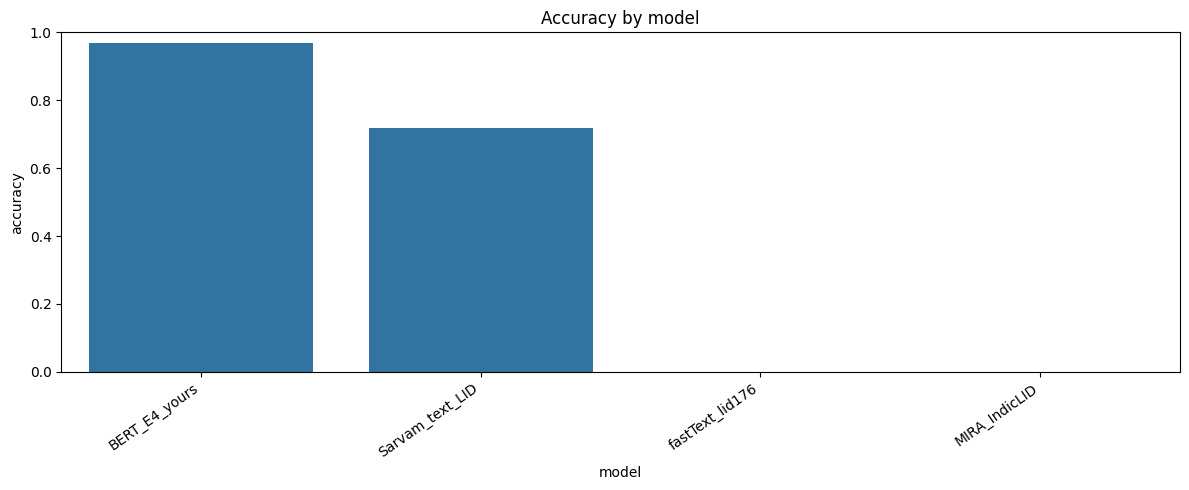

/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


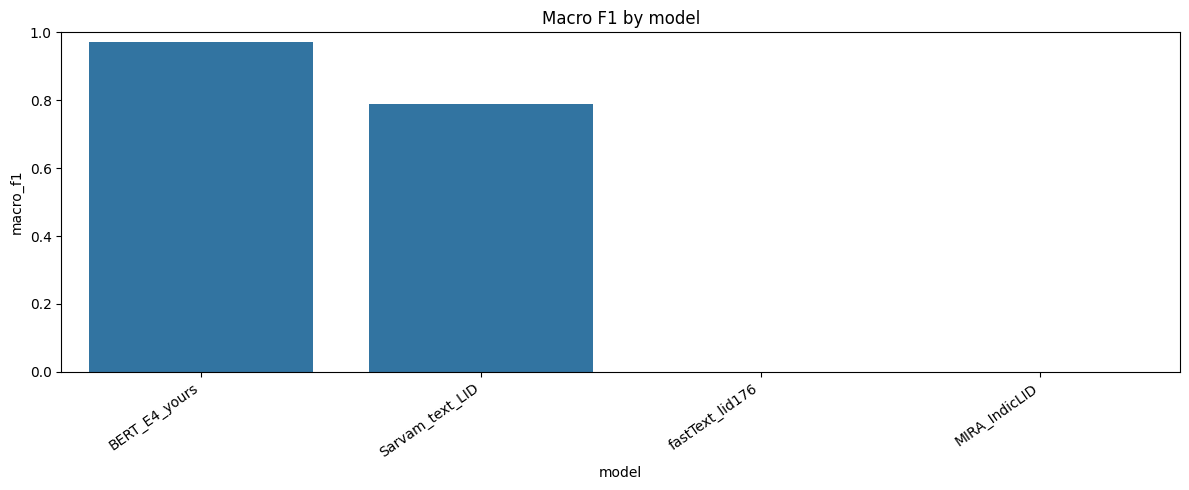

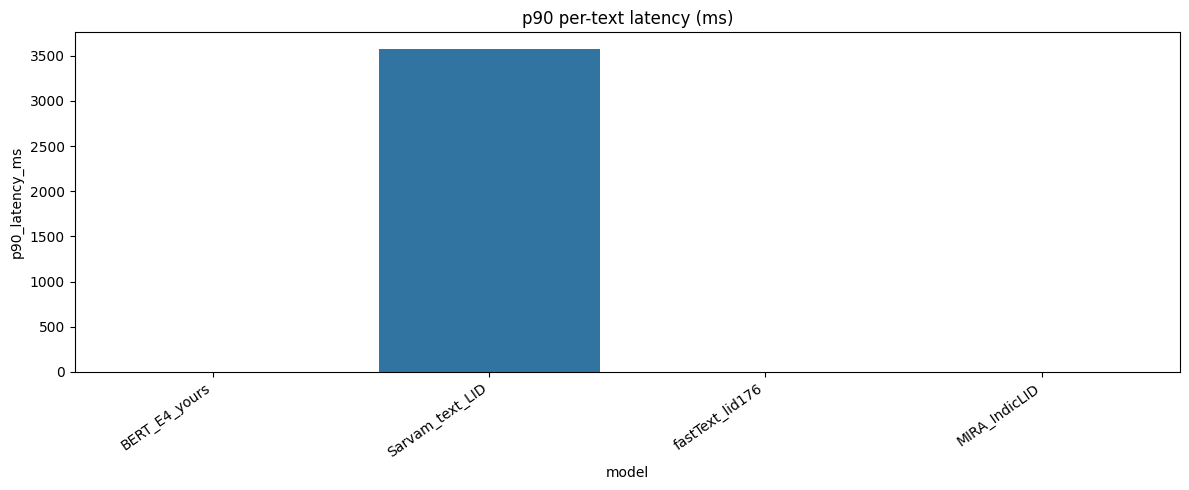

/tmp/ipykernel_180/20013526.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


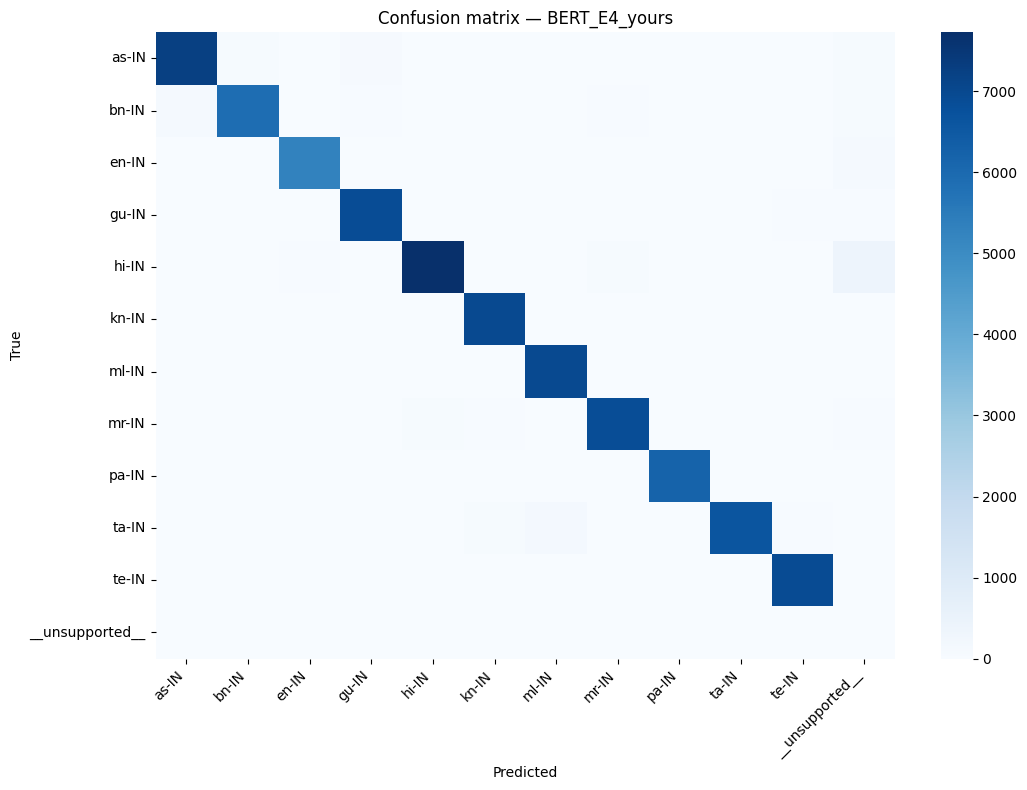

/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


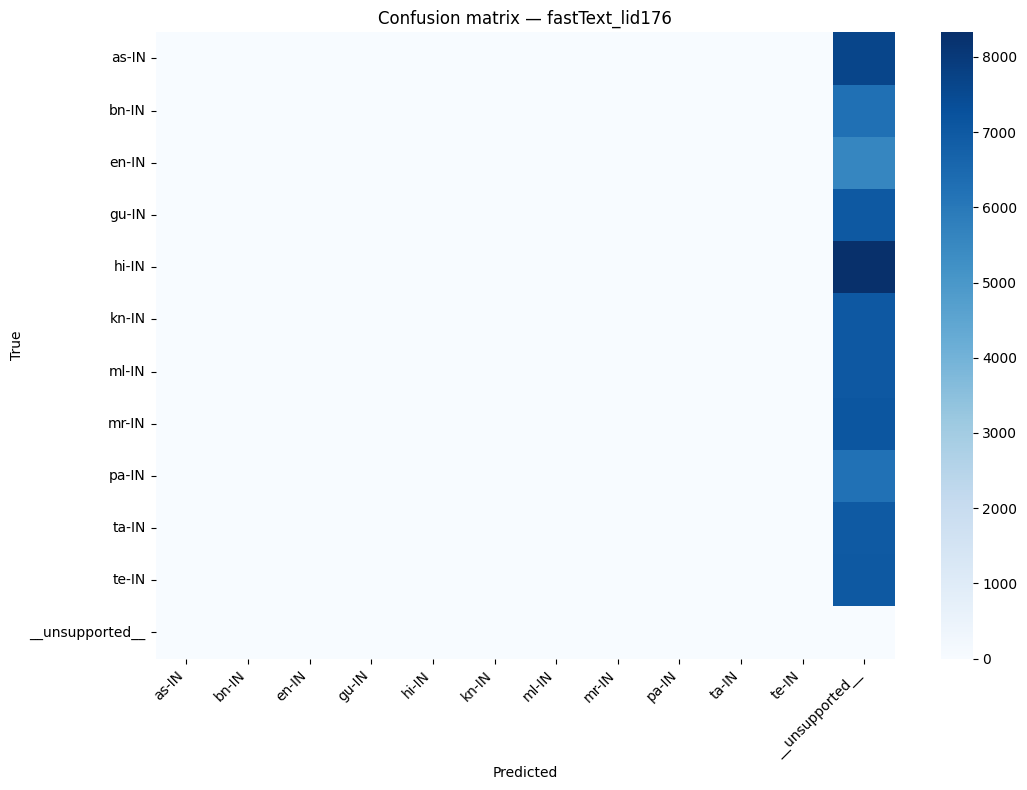

/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)
/tmp/ipykernel_180/347114256.py:53: RuntimeWarning: coroutine 'sarvam_predict_one' was never awaited
  pred, script = sarvam_predict_one(client, text)


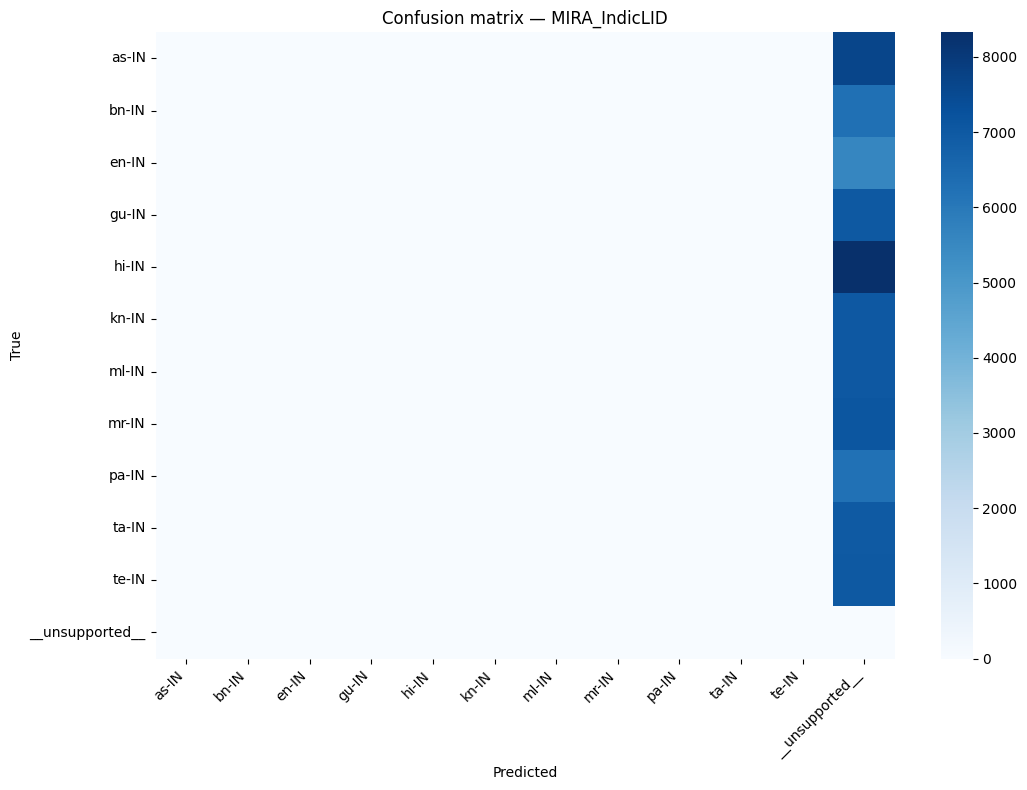

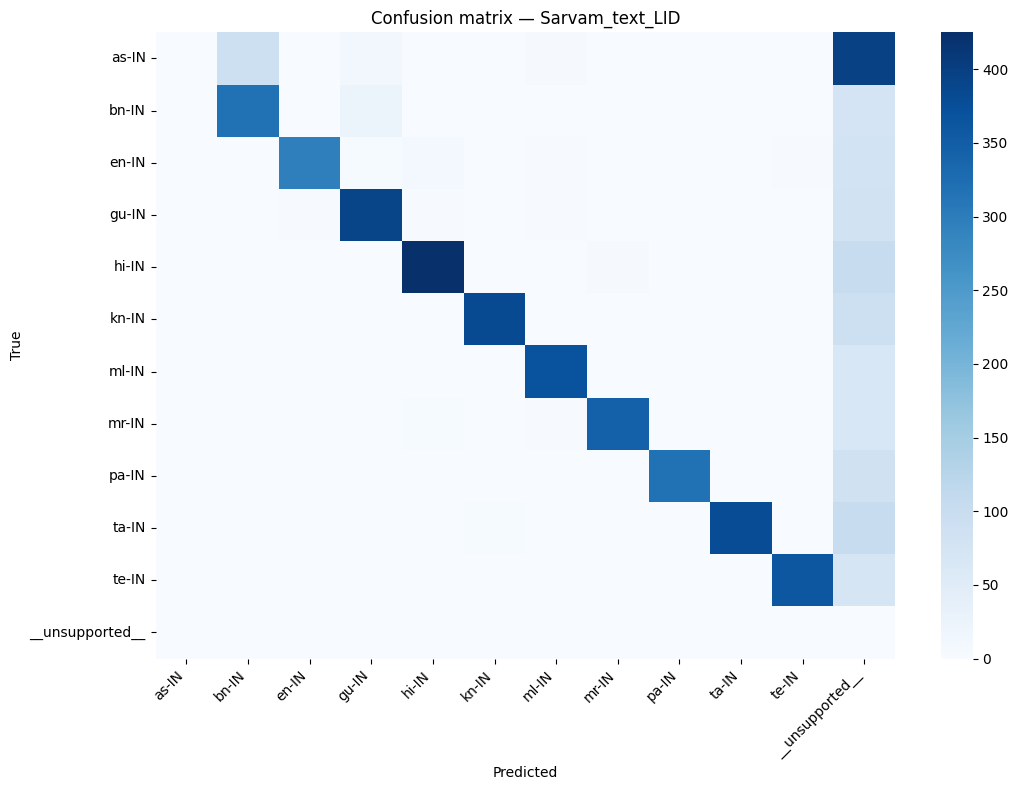

In [63]:
if not comparison_df.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(data=comparison_df, x="model", y="accuracy")
    plt.xticks(rotation=35, ha="right")
    plt.ylim(0, 1)
    plt.title("Accuracy by model")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))
    sns.barplot(data=comparison_df, x="model", y="macro_f1")
    plt.xticks(rotation=35, ha="right")
    plt.ylim(0, 1)
    plt.title("Macro F1 by model")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))
    sns.barplot(data=comparison_df, x="model", y="p90_latency_ms")
    plt.xticks(rotation=35, ha="right")
    plt.title("p90 per-text latency (ms)")
    plt.tight_layout()
    plt.show()

# Confusion matrix for each model that has predictions
for model_name, preds in predictions_by_model.items():
    n_eval = min(len(preds), len(y_true))
    pp = [normalize_label(x) for x in preds[:n_eval]]
    cm_labels = TARGET_LABELS + ["__unsupported__"]
    cm = confusion_matrix(y_true[:n_eval], pp, labels=cm_labels)
    plt.figure(figsize=(11, 8))
    sns.heatmap(cm, cmap="Blues", xticklabels=cm_labels, yticklabels=cm_labels)
    plt.title(f"Confusion matrix — {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 9. Export results

Download the files for reports and your presentation:
- `comparison_df.csv`
- `per_language_df.csv`
- `predictions_df.csv`
- `benchmark_results.xlsx` (three sheets)

In [ ]:
OUT_DIR = Path("/content/lid_benchmark_outputs")
OUT_DIR.mkdir(exist_ok=True)

comparison_df.to_csv(OUT_DIR / "comparison_df.csv", index=False)
per_language_df.to_csv(OUT_DIR / "per_language_df.csv", index=False)
prediction_output.to_csv(OUT_DIR / "predictions_df.csv", index=False)

with pd.ExcelWriter(OUT_DIR / "benchmark_results.xlsx", engine="openpyxl") as writer:
    comparison_df.to_excel(writer, sheet_name="comparison", index=False)
    per_language_df.to_excel(writer, sheet_name="per_language", index=False)
    prediction_output.to_excel(writer, sheet_name="predictions", index=False)

zip_out = "/content/lid_benchmark_outputs.zip"
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in OUT_DIR.iterdir():
        zf.write(f, arcname=f.name)

print("Saved outputs:", list(OUT_DIR.iterdir()))
from google.colab import files
files.download(zip_out)

## Benchmark caveats / reproducibility checklist

- Run a 500–1,000 row smoke test first; only then set `MAX_ROWS = None`.
- For a strict apples-to-apples comparison, every model must use the same rows. If Sarvam stops due to quota, report it separately as a pilot.
- Save the exact model revision, API date, runtime hardware, batch size, and max sequence length with your report.
- fastText `lid.176` is a general multilingual baseline, not Indic-specialized. MIRA-IndicLID is an Indic-focused fastText model.
- IndicLID uses multiple model components and script-aware outputs; use the official inference implementation rather than only one component if your goal is the full IndicLID baseline.
- Latency numbers in this notebook include tokenization for transformer models and are measured in batches divided by batch size; they are useful for approximate comparison, not a substitute for a dedicated real-time single-turn latency test.
- Sarvam text LID has a 1,000-character input limit and can return `language_code`/`script_code`; the endpoint does not document confidence in the response schema.

In [3]:
print("fastText raw predictions:")
print(df["pred_fastText_lid176"].value_counts(dropna=False).head(20))

print("\nIndicLID raw predictions:")
print(df["pred_MIRA_IndicLID"].value_counts(dropna=False).head(20))

print("\nGround-truth labels:")
print(df["label"].value_counts())

In [92]:
# Inspect raw predictions BEFORE normalize_label()

test_texts = texts[:20]

for model_name, model_obj in fasttext_models.items():
    print(f"\n{'=' * 60}")
    print("MODEL:", model_name)

    for text in test_texts[:10]:
        try:
            labels, probs = model_obj.predict(
                str(text).replace("\n", " "),
                k=1
            )

            raw_label = labels[0]
            cleaned_label = raw_label.replace("__label__", "")

            print({
                "text": str(text)[:70],
                "raw_label": raw_label,
                "cleaned_label": cleaned_label,
                "confidence": float(probs[0])
            })

        except Exception as e:
            print("ERROR:", repr(e))


MODEL: fastText_lid176
ERROR: ValueError('Unable to avoid copy while creating an array as requested.\nIf using `np.array(obj, copy=False)` replace it with `np.asarray(obj)` to allow a copy when needed (no behavior change in NumPy 1.x).\nFor more details, see https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword.')
ERROR: ValueError('Unable to avoid copy while creating an array as requested.\nIf using `np.array(obj, copy=False)` replace it with `np.asarray(obj)` to allow a copy when needed (no behavior change in NumPy 1.x).\nFor more details, see https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword.')
ERROR: ValueError('Unable to avoid copy while creating an array as requested.\nIf using `np.array(obj, copy=False)` replace it with `np.asarray(obj)` to allow a copy when needed (no behavior change in NumPy 1.x).\nFor more details, see https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to